# HDB Rentals: interpreting the neighbour-premium GNN

`scripts/gnn_neighbour_premiums.py` gives each rental two kinds of past-rent information:

- **its own block's premium**, as row inputs (notebook 10's E1: block and block + flat type premiums of
  relative rent and the block + flat type row count; out-of-fold for fit rows);
- **its direct neighbours' premiums**, through a one-hop channel read after message passing (never its own).

On the holdout the channel changes overall RMSE by nothing (482.08 vs 482.04 without it), and helps a little
only for blocks with almost no past rentals of that flat type. This notebook asks *why*, with the
explainer, checks and conventions of `11_interpretability.ipynb`:

1. Does the model lean on neighbours' premiums more when its own block has little history?
2. What happens to predictions if the neighbours' premiums are replaced by an average block's?
3. Do the channel's gates (a diagnostic) tell the same story as the attributions?
4. Are the explanations exact and complete for this model?

| | |
|---|---|
| **Models** | `NeighbourPremiumGNN` as `GNN_uniform` and as `MLP_matched` (message passing off, premium channel on), seed 0 |
| **Data** | fit 2021-01 to 2023-12, scored 2024-01 to 2025-03; epochs from that script's tuning split |
| **Explained** | 120 random holdout rentals per history bucket (0, 1-2, 3-5, 6-10, >10 earlier fit rentals of the same block + flat type) |
| **Baseline** | mean fit record, mean fit block, mean fit-block premium |

## Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "scripts")]

import gnn_neighbour_premiums as gnp  # imports torch before LightGBM
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from hdb_rentals.explain import SubgraphExplainer

gpb, cmp, ewg = gnp.gpb, gnp.cmp, gnp.ewg
torch.set_num_threads(4)
OUT = ROOT / "outputs" / "12_interpretability_premiums"
(OUT / "models").mkdir(parents=True, exist_ok=True)
RETRAIN = False          # True retrains instead of loading outputs/12_interpretability_premiums/models
PER_BUCKET, IG_STEPS = 120, 32
BUCKETS = gnp.BUCKETS

BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
INK, INK2, GRID, SURFACE, NEUTRAL = "#0b0b0b", "#52514e", "#e2e1dc", "#fcfcfb", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
    "axes.titlesize": 11, "font.size": 9.5, "figure.dpi": 110, "axes.axisbelow": True,
})

## Data and models

Built exactly as `gnn_neighbour_premiums.main` builds its holdout split.

In [2]:
hdb = cmp.nb10_block_table()
tr, frames = gpb.nb10_premium_frames(hdb)
fit_rows, val_rows, node_rows = frames["holdout"]
rent, blocks, graph = ewg.rent, ewg.blocks, ewg.GRAPH
d = rent.RENT_APPROVAL_DATE
prem_rows = pd.concat([fit_rows, val_rows])
fit = gpb.with_premiums(rent[d < cmp.HOLD_START], prem_rows)
hold = gpb.with_premiums(rent[(d >= cmp.HOLD_START) & (d < cmp.HOLD_END)], prem_rows)
hold["history"] = prem_rows.set_index("row_id")["BLOCK_FT_N"].reindex(hold.row_id).to_numpy()
hold["bucket"] = pd.cut(hold.history, BUCKETS[0], labels=BUCKETS[1])

x = blocks[cmp.KEY].merge(node_rows, on=cmp.KEY, how="left", validate="m:1")[gpb.NODE_PREM] \
    .fillna({"NODE_BLOCK_PREM": 1.0, "NODE_LOG_N": 0.0}).to_numpy(float)
x[:, 0] = np.log(x[:, 0])
PREMIUMS = torch.tensor((x - x.mean(0)) / x.std(0), dtype=torch.float32)
bundle = cmp.prepare(fit, [hold], "damped", list(ewg.BLOCK_NUM), gpb.PREM)
bundle["node_premiums"] = PREMIUMS
part, NODES = bundle["parts"][1], bundle["nodes"]

BLOCK_NUM, BLOCK_CAT = list(ewg.BLOCK_NUM), ewg.BLOCK_CAT + ["SUBZONE"]
REC_NUM, REC_CAT = ["FLOOR_AREA_SQM", "FLAT_AGE", *gpb.PREM], ["FLAT_TYPE", "FLAT_MODEL"]
FIT_BLOCKS = np.sort(fit.block_id.unique())
bp = ewg.preprocessor(BLOCK_NUM, BLOCK_CAT).fit(blocks.iloc[FIT_BLOCKS])
rp = ewg.preprocessor(REC_NUM, REC_CAT).fit(fit)
assert np.allclose(bp.transform(blocks), NODES.numpy()) and np.allclose(rp.transform(hold), part["record"].numpy())


def source_column(name, cat):
    kind, rest = name.split("__", 1)
    if kind == "num":
        return rest.removeprefix("missingindicator_")
    return next(c for c in cat if rest.startswith(c + "_"))


REC_COLS = np.array([source_column(n, REC_CAT) for n in rp.get_feature_names_out()])
OWN_PREMIUM = np.isin(REC_COLS, gpb.PREM)
print(f"{len(fit):,} fit and {len(hold):,} holdout rows; record columns: {len(REC_COLS)} "
      f"({OWN_PREMIUM.sum()} own-block premium); block columns: {NODES.shape[1]}; neighbour premium columns: "
      f"{PREMIUMS.shape[1]} ({', '.join(gpb.NODE_PREM)})")
print("holdout rows per history bucket:", hold.bucket.value_counts().reindex(BUCKETS[1]).to_dict())

105,837 fit and 44,163 holdout rows; record columns: 30 (3 own-block premium); block columns: 254; neighbour premium columns: 2 (NODE_BLOCK_PREM, NODE_LOG_N)
holdout rows per history bucket: {'0': 635, '1-2': 3167, '3-5': 7100, '6-10': 11305, '>10': 21956}


In [3]:
reported = pd.read_csv(ROOT / "outputs/gnn_neighbour_premiums/results.csv").query("split == 'holdout' and premiums == 'row+nbr'")
epochs = reported.dropna(subset=["epochs"]).set_index("model").epochs.astype(int)


def get_model(kind):
    path = OUT / "models" / f"premiums_{kind}_seed0.pt"
    model = gnp.NeighbourPremiumGNN(kind, NODES.shape[1], part["record"].shape[1], PREMIUMS)
    if path.exists() and not RETRAIN:
        missing, unexpected = model.load_state_dict(torch.load(path, weights_only=True), strict=False)
        assert not unexpected and set(missing) <= {n for n, _ in model.named_buffers()}
        return model.eval()
    fitted, _, _ = gnp.train(kind, bundle, 0, int(epochs[kind]))
    torch.save(dict(fitted.named_parameters()), path)  # parameters only; graph buffers come from the class
    return fitted.eval()


models = {"GNN": get_model("GNN_uniform"), "MLP (graph off)": get_model("MLP_matched")}


def rmse(pred, y):
    return float(np.sqrt(np.mean((pred - y) ** 2)))


preds = {name: ewg.predict(m, bundle, part) for name, m in models.items()}
check = pd.DataFrame({name: {"holdout RMSE here": rmse(p, part["y"]),
                             "reported": reported.set_index("model").rmse[kind]}
                      for (name, p), kind in zip(preds.items(), ["GNN_uniform", "MLP_matched"])}).T
by_bucket = pd.DataFrame({name: pd.Series((p - part["y"]) ** 2).groupby(hold.bucket.to_numpy(), observed=False).mean() ** 0.5
                          for name, p in preds.items()}).reindex(BUCKETS[1])
by_bucket["rows"] = hold.bucket.value_counts().reindex(BUCKETS[1])
display(check.round(2))
by_bucket.round(1)

,holdout RMSE here,reported
GNN,482.09,482.08
MLP (graph off),482.14,482.11


,GNN,MLP (graph off),rows
0,575.9,576.6,635
1-2,507.5,507.0,3167
3-5,500.7,500.5,7100
6-10,485.5,485.5,11305
>10,467.2,467.5,21956


## 1. Own premium vs neighbours' premiums, by how much history the block has

Mean absolute contribution in dollars per rental, by input group. If the channel fills gaps, neighbours'
premiums should matter more where the block has no or few past rentals of that flat type, and the block's own
premium should take over as its history grows.

In [4]:
explainer = SubgraphExplainer(graph.edge_index, graph.n_nodes)
NODE_BASE = NODES[FIT_BLOCKS].mean(0)
REC_BASE = bundle["parts"][0]["record"].mean(0)
PREM_BASE = PREMIUMS[FIT_BLOCKS].mean(0)
dollars = bundle["std"] * part["scale"]

rng = np.random.default_rng(0)
rows = np.sort(np.concatenate([rng.choice(np.flatnonzero(hold.bucket.to_numpy() == b), PER_BUCKET, replace=False)
                               for b in BUCKETS[1]]))


@torch.no_grad()
def full_outputs(model):
    return model(NODES, part).numpy()


def explain(model):
    f_full = full_outputs(model)
    out = []
    for i in rows:
        e = explainer.explain(model, NODES, part["record"][i], int(part["ids"][i]), row=i, steps=IG_STEPS,
                              node_base=NODE_BASE, record_base=REC_BASE, extra={"premiums": (PREMIUMS, PREM_BASE)})
        dd = dollars[i]
        prem = e.extra["premiums"]
        out.append(dict(row=i, bucket=hold.bucket.iloc[i],
                        flat=np.abs(e.record[~OWN_PREMIUM].sum()) * dd,
                        own_premium=np.abs(e.record[OWN_PREMIUM].sum()) * dd,
                        own_location=np.abs(e.own.sum()) * dd,
                        neighbour_features=np.abs(e.neighbours.sum()) * dd,
                        neighbour_premiums=np.abs(np.delete(prem, e.local, axis=0).sum()) * dd,
                        own_premium_via_channel=np.abs(prem[e.local]).sum(),
                        signed_neighbour_premiums=np.delete(prem, e.local, axis=0).sum() * dd,
                        total=e.total(), gap=e.output - e.baseline, sub=e.output, full=float(f_full[i]),
                        completeness_dollars=abs(e.total() - (e.output - e.baseline)) * dd))
    return pd.DataFrame(out)


attr = {name: explain(m) for name, m in models.items()}
GROUPS = {"flat": "Flat attributes", "own_premium": "Own block's premium", "own_location": "Own block's location",
          "neighbour_features": "Neighbours' features", "neighbour_premiums": "Neighbours' premiums"}
tables = {name: a.groupby("bucket", observed=False)[list(GROUPS)].mean().rename(columns=GROUPS).reindex(BUCKETS[1])
          for name, a in attr.items()}
for name, t in tables.items():
    t["neighbours' premiums / own premium"] = t["Neighbours' premiums"] / t["Own block's premium"]
    print(name)
    display(t.round(1))

GNN


,Flat attributes,Own block's premium,Own block's location,Neighbours' features,Neighbours' premiums,neighbours' premiums / own premium
bucket,,,,,,
0,324.1,68.5,133.0,29.8,63.4,0.9
1-2,288.3,126.0,107.5,24.8,40.3,0.3
3-5,255.9,118.6,81.7,24.0,38.1,0.3
6-10,232.1,108.9,83.3,22.0,39.3,0.4
>10,285.5,82.5,87.8,24.6,48.0,0.6


MLP (graph off)


,Flat attributes,Own block's premium,Own block's location,Neighbours' features,Neighbours' premiums,neighbours' premiums / own premium
bucket,,,,,,
0,313.2,66.4,179.1,0.0,72.9,1.1
1-2,281.8,123.0,145.1,0.0,41.9,0.3
3-5,249.9,114.6,106.7,0.0,37.3,0.3
6-10,227.9,104.6,111.2,0.0,38.6,0.4
>10,278.9,77.4,117.5,0.0,49.7,0.6


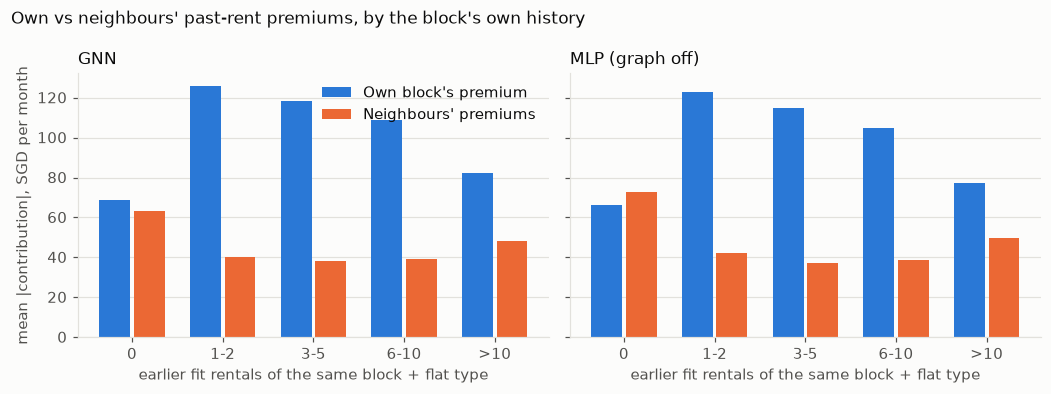

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6), sharey=True)
x = np.arange(len(BUCKETS[1]))
for ax, (name, t) in zip(axes, tables.items()):
    for j, (col, color) in enumerate([("Own block's premium", BLUE), ("Neighbours' premiums", ORANGE)]):
        ax.bar(x + (j - 0.5) * 0.38, t[col], width=0.34, color=color, label=col)
    ax.set_xticks(x, BUCKETS[1])
    ax.set_xlabel("earlier fit rentals of the same block + flat type")
    ax.grid(axis="x", visible=False)
    ax.set_title(name)
axes[0].set_ylabel("mean |contribution|, SGD per month")
axes[0].legend(frameon=False)
fig.suptitle("Own vs neighbours' past-rent premiums, by the block's own history", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "premiums_by_history.png", bbox_inches="tight")
plt.show()

## 2. Replacing the neighbours' premiums with an average block's

Every block's channel input is set to the mean fit-block premium (an average neighbourhood, inside the range
the model was trained on, unlike deleting edges). The change in each prediction, by history bucket.

In [6]:
@torch.no_grad()
def without_neighbour_premiums(model):
    kept = model.premiums.clone()
    model.premiums = PREM_BASE.expand_as(kept).clone()
    out = model(NODES, part).numpy()
    model.premiums = kept
    return out


replace = []
for name, m in models.items():
    delta = (full_outputs(m) - without_neighbour_premiums(m)) * dollars
    g = pd.Series(np.abs(delta)).groupby(hold.bucket.to_numpy(), observed=False)
    replace.append(pd.DataFrame({"model": name, "bucket": BUCKETS[1],
                                 "mean |Δ$|": g.mean().reindex(BUCKETS[1]).to_numpy(),
                                 "95th pct |Δ$|": g.quantile(0.95).reindex(BUCKETS[1]).to_numpy()}))
replace = pd.concat(replace).pivot(index="bucket", columns="model").reindex(BUCKETS[1])
replace.round(1)

mean |Δ$|                 95th pct |Δ$|                
model        GNN MLP (graph off)           GNN MLP (graph off)
bucket                                                        
0           74.6            85.8         171.3           179.9
1-2         48.5            50.9         166.2           166.2
3-5         38.2            38.6         156.3           147.8
6-10        39.4            39.2         169.2           156.6
>10         50.9            51.8         194.2           175.5

## 3. The channel's gates (diagnostic only)

The channel adds `gate × message` to each block's embedding; `gnn_neighbour_premiums.py` reported that the mean
gate falls as a block's history grows. Gates are like attention weights: they show how much is let through,
not how much it changes the prediction, so they are set against the attributions from section 1.

In [7]:
gate_rows = []
for name, m in models.items():
    full_outputs(m)                                   # sets m.last_premium_gate for every block
    g = m.last_premium_gate.mean(1).numpy()[part["ids"].numpy()]
    s = pd.Series(g).groupby(hold.bucket.to_numpy(), observed=False).mean().reindex(BUCKETS[1])
    gate_rows.append(pd.DataFrame({"model": name, "bucket": BUCKETS[1], "mean gate": s.to_numpy(),
                                   "mean |IG| on neighbours' premiums $": tables[name]["Neighbours' premiums"].to_numpy()}))
gates = pd.concat(gate_rows).pivot(index="bucket", columns="model").reindex(BUCKETS[1])
gates.round(3)

mean gate                 mean |IG| on neighbours' premiums $  \
model        GNN MLP (graph off)                                 GNN   
bucket                                                                 
0          0.145           0.141                              63.410   
1-2        0.136           0.133                              40.295   
3-5        0.132           0.129                              38.110   
6-10       0.129           0.127                              39.269   
>10        0.121           0.119                              48.028   

                        
model  MLP (graph off)  
bucket                  
0               72.947  
1-2             41.939  
3-5             37.297  
6-10            38.601  
>10             49.651

## 4. Checks

In [8]:
checks = pd.DataFrame({name: {"max |subgraph − full| (model units)": (a["sub"] - a["full"]).abs().max(),
                              "median completeness error $": a.completeness_dollars.median(),
                              "max completeness error $": a.completeness_dollars.max(),
                              "max |IG| on own premium via channel": a.own_premium_via_channel.max(),
                              "max |IG| on neighbours' features": a.neighbour_features.max()}
                       for name, a in attr.items()}).T
checks.style.format("{:.2g}")

,max |subgraph − full| (model units),median completeness error $,max completeness error $,max |IG| on own premium via channel,max |IG| on neighbours' features
GNN,2.4e-07,0.67,9.7,0,3e+02
MLP (graph off),2.4e-07,1,12,0,0


## Summary

From this run: 600 holdout rentals, 120 per history bucket.

- **The explanations are exact and respect the design.** The subgraph matches the full graph to 2e-7, and the
  median completeness error is under $1. A block's own premium never comes back through the channel
  (attribution exactly 0), and the graph-free version gives neighbours' features exactly 0.
- **The model leans on neighbours' premiums where its own block has no history.**
  - With no earlier fit rentals of that block + flat type, neighbours' premiums move a prediction by $63 on
    average, about as much as the block's own premium ($68, which then falls back to a block-wide prior).
  - With 1 to 10 earlier rentals, the block's own premium dominates ($109–126 vs $38–40).
  - Replacing the neighbours' premiums with an average block's shows the same picture: $75 at zero history,
    $38–51 elsewhere.
- **That only pays off in the thin slice.** By-bucket RMSE improves only where history is 0 (this run:
  575.9, against 577.8 for the same GNN without the channel in `gnn_neighbour_premiums.py`). Those rows are
  635 of 44,163. Elsewhere the channel shifts predictions by about $40 without making them more accurate,
  as in notebook 11, where neighbours' features repeat what the block already has.
- **The pattern is in the channel, not in message passing.** The graph-free MLP with the same channel shows
  the same pattern (zero-history bucket: $73 from neighbours' premiums vs $66 own).
- **The gates and the attributions disagree for well-documented blocks.** The mean gate falls steadily with
  history (0.145 to 0.121). The attribution to neighbours' premiums is U-shaped: $63 at zero history, $38 in
  the middle, back up to $48 above 10. This is the survey's warning about attention in practice: a lower gate
  does not mean the input matters less, so gates should not be reported as explanations.